# 手写数字识别实验 

c:\Users\59718\AppData\Local\Programs\python\Python311\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


当前训练设备： cpu
开始训练...


c:\Users\59718\AppData\Local\Programs\python\Python311\Lib\site-packages\paddle\nn\layer\norm.py:885: UserWarning: When training, we now always track global mean and variance.
  warnings.warn(
c:\Users\59718\AppData\Local\Programs\python\Python311\Lib\site-packages\paddle\pir\math_op_patch.py:241: UserWarning: Tensor do not have 'place' interface for pir graph mode, try not to use it. None will be returned.
  warnings.warn(


Epoch [1/10] | Train Loss: 0.3702 | Train Acc: 7.2040 | Test Acc: 7.0576
Epoch [2/10] | Train Loss: 0.1702 | Train Acc: 7.2483 | Test Acc: 7.0738
Epoch [3/10] | Train Loss: 0.1308 | Train Acc: 7.3002 | Test Acc: 7.0715
Epoch [4/10] | Train Loss: 0.1088 | Train Acc: 7.2767 | Test Acc: 7.0715
Epoch [5/10] | Train Loss: 0.0961 | Train Acc: 7.2877 | Test Acc: 7.0738
Epoch [6/10] | Train Loss: 0.0862 | Train Acc: 7.2947 | Test Acc: 7.0752
Epoch [7/10] | Train Loss: 0.0764 | Train Acc: 7.2803 | Test Acc: 7.0716
Epoch [8/10] | Train Loss: 0.0714 | Train Acc: 7.2654 | Test Acc: 7.0729
Epoch [9/10] | Train Loss: 0.0641 | Train Acc: 7.2615 | Test Acc: 7.0712
Epoch [10/10] | Train Loss: 0.0586 | Train Acc: 7.2858 | Test Acc: 7.0739


C:\Users\59718\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21464 (\N{CJK UNIFIED IDEOGRAPH-53D8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\59718\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\59718\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\59718\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\59718\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py

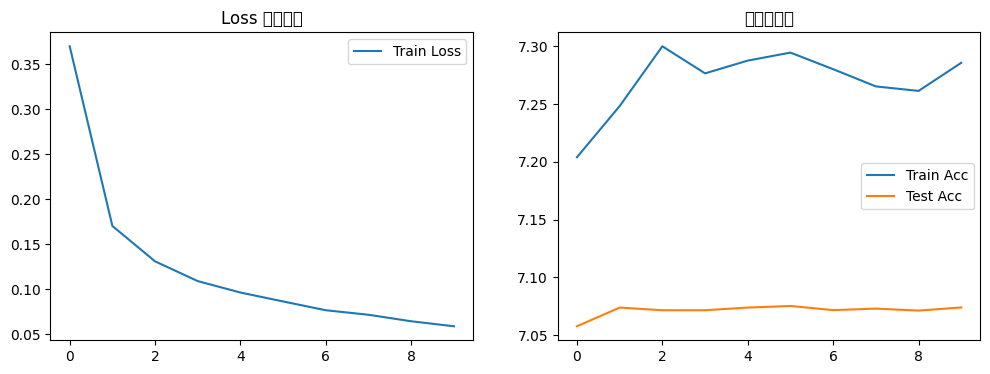

模型已保存：mnist_final.pdparams
静态图推理模型已导出：inference/mnist


ValueError: The ``path`` (inference/mnist) to load model not exists. Please make sure that *.pdmodel(json) exists or don't using ``skip_forward=True`` to jit.save.

: 

In [ ]:
import os
import paddle
import paddle.nn as nn
import paddle.nn.functional as F
from paddle.vision.datasets import MNIST
from paddle.vision.transforms import Compose, Normalize
from paddle.io import DataLoader
from paddle.static import InputSpec
import matplotlib.pyplot as plt
import numpy as np

# ======================
# 全局配置
# ======================
paddle.seed(42)
np.random.seed(42)
# 自动识别设备：有GPU用GPU，没有用CPU
paddle.set_device('gpu' if paddle.is_compiled_with_cuda() else 'cpu')
print("当前训练设备：", paddle.device.get_device())

# ======================
# 1. 数据准备模块
# ======================
def get_data_loaders(batch_size=64):
    transform = Compose([Normalize(mean=[127.5], std=[127.5], data_format='CHW')])
    
    train_dataset = MNIST(mode='train', transform=transform)
    test_dataset = MNIST(mode='test', transform=transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    
    return train_loader, test_loader

# ======================
# 2. 网络模型定义（改进版CNN）
# ======================
class MNIST_CNN(nn.Layer):
    def __init__(self):
        super(MNIST_CNN, self).__init__()
        self.conv1 = nn.Conv2D(1, 32, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2D(32)
        self.pool = nn.MaxPool2D(2, 2)
        self.conv2 = nn.Conv2D(32, 64, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2D(64)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    @paddle.jit.to_static
    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = paddle.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# ======================
# 3. 损失函数 & 优化器配置
# ======================
def build_model_optimizer(learning_rate=0.001):
    model = MNIST_CNN()
    optimizer = paddle.optimizer.Adam(learning_rate=learning_rate, parameters=model.parameters())
    return model, optimizer

# ======================
# 4. 训练 & 评估函数
# ======================
def train_one_epoch(model, optimizer, train_loader):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for img, label in train_loader:
        pred = model(img)
        loss = F.cross_entropy(pred, label)
        loss.backward()
        optimizer.step()
        optimizer.clear_grad()

        total_loss += loss.item()
        pred_cls = paddle.argmax(pred, axis=1)
        correct += (pred_cls == label).sum().item()
        total += label.shape[0]
    return total_loss / len(train_loader), correct / total

def evaluate(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    with paddle.no_grad():
        for img, label in test_loader:
            pred = model(img)
            pred_cls = paddle.argmax(pred, axis=1)
            correct += (pred_cls == label).sum().item()
            total += label.shape[0]
    return correct / total

# ======================
# 5. 完整训练流程 + 可视化
# ======================
def full_train(epochs=10):
    train_loader, test_loader = get_data_loaders(batch_size=64)
    model, optimizer = build_model_optimizer(learning_rate=0.001)

    train_loss_history = []
    train_acc_history = []
    test_acc_history = []

    print("开始训练...")
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, optimizer, train_loader)
        test_acc = evaluate(model, test_loader)

        train_loss_history.append(train_loss)
        train_acc_history.append(train_acc)
        test_acc_history.append(test_acc)

        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | "
              f"Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    # 绘制曲线
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(train_loss_history, label='Train Loss')
    plt.title('Loss 变化曲线')
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(train_acc_history, label='Train Acc')
    plt.plot(test_acc_history, label='Test Acc')
    plt.title('准确率曲线')
    plt.legend()
    plt.show()

    # 保存最终模型
    paddle.save(model.state_dict(), "mnist_final.pdparams")
    paddle.save(optimizer.state_dict(), "mnist_final.pdopt")
    print("模型已保存：mnist_final.pdparams")
    
    return model

# ======================
# 6. 断点恢复训练（2.9节内容）
# ======================
def resume_train(checkpoint_epoch=0, total_epochs=10):
    train_loader, test_loader = get_data_loaders()
    model, optimizer = build_model_optimizer()

    model.set_state_dict(paddle.load(f"checkpoint/mnist_epoch{checkpoint_epoch}.pdparams"))
    optimizer.set_state_dict(paddle.load(f"checkpoint/mnist_epoch{checkpoint_epoch}.pdopt"))
    print(f"从 epoch {checkpoint_epoch} 恢复训练")

    for epoch in range(checkpoint_epoch, total_epochs):
        train_loss, train_acc = train_one_epoch(model, optimizer, train_loader)
        test_acc = evaluate(model, test_loader)
        print(f"Resume Epoch {epoch} | Loss: {train_loss:.4f} | Test Acc: {test_acc:.4f}")

# ======================
# 7. 动静转换模型导出与推理（2.10节）
# ======================
def export_static_model():
    model = MNIST_CNN()
    model.set_state_dict(paddle.load("mnist_final.pdparams"))
    model.eval()

    paddle.jit.save(
        layer=model,
        path="inference/mnist",
        input_spec=[InputSpec(shape=[None, 1, 28, 28], dtype='float32')]
    )
    print("静态图推理模型已导出：inference/mnist")

def static_inference():
    model = paddle.jit.load("inference/mnist")
    model.eval()
    _, test_loader = get_data_loaders(batch_size=1)
    img, label = next(iter(test_loader))
    pred = model(img)
    print("真实标签：", label.numpy()[0])
    print("预测标签：", paddle.argmax(pred).numpy()[0])

# ======================
# 8. 不同优化器 / 损失函数 对比实验
# ======================
def compare_optimizers():
    train_loader, test_loader = get_data_loaders(32)
    results = {}

    for opt_name in ['SGD', 'RMSprop', 'Adam']:
        model = MNIST_CNN()
        if opt_name == 'SGD':
            opt = paddle.optimizer.SGD(0.01, parameters=model.parameters())
        elif opt_name == 'RMSprop':
            opt = paddle.optimizer.RMSProp(0.001, parameters=model.parameters())
        else:
            opt = paddle.optimizer.Adam(0.001, parameters=model.parameters())

        print(f"\n===== 训练优化器：{opt_name} =====")
        for e in range(3):
            loss, acc = train_one_epoch(model, opt, train_loader)
            test_acc = evaluate(model, test_loader)
            print(f"Epoch {e} | Test Acc: {test_acc:.4f}")
        results[opt_name] = test_acc

    print("\n===== 优化器对比结果 =====")
    for k, v in results.items():
        print(f"{k}:\t{v:.4f}")

# ======================
# 主程序入口
# ======================
if __name__ == "__main__":
    # 1. 完整训练
    model = full_train(epochs=10)

    # 2. 导出静态图（部署）
    export_static_model()

    # 3. 静态图推理测试
    static_inference()

    # 4. 优化器对比实验（实验报告核心）
    compare_optimizers()

    # 5. 断点恢复训练
    # resume_train(checkpoint_epoch=0, total_epochs=5)